import all libraries


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score,
    GridSearchCV, TunedThresholdClassifierCV,
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.feature_selection import mutual_info_classif, chi2, f_classif
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    recall_score, f1_score, roc_auc_score, roc_curve,
)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

import warnings
warnings.filterwarnings('ignore')

print("✅ All libraries imported successfully")

✅ All libraries imported successfully


Load and explore data

In [3]:
# Load dataset
df = pd.read_csv('data/Prostate_Cancer_v2.csv')

print(f" Dataset loaded")
print(f"   Shape     : {df.shape[0]} rows × {df.shape[1]} columns")
print(f"   Columns   : {df.columns.tolist()}")
print()

# Class distribution
print(" Target Distribution (diagnosis_result):")
print(df['diagnosis_result'].value_counts())
print(df['diagnosis_result'].value_counts(normalize=True).round(3))
print()

# Missing values
print(" Missing Values:")
print(df.isnull().sum())
print()

# Basic stats
print("📊 Basic Statistics:")
df.describe()

 Dataset loaded
   Shape     : 2000 rows × 18 columns
   Columns   : ['id', 'age', 'BMI', 'PSA_level', 'free_PSA_ratio', 'testosterone_level', 'alkaline_phosphatase', 'family_history', 'smoking_status', 'radius', 'texture', 'perimeter', 'area', 'smoothness', 'compactness', 'symmetry', 'fractal_dimension', 'diagnosis_result']

 Target Distribution (diagnosis_result):
diagnosis_result
M    1009
B     991
Name: count, dtype: int64
diagnosis_result
M    0.504
B    0.496
Name: proportion, dtype: float64

 Missing Values:
id                      0
age                     0
BMI                     0
PSA_level               0
free_PSA_ratio          0
testosterone_level      0
alkaline_phosphatase    0
family_history          0
smoking_status          0
radius                  0
texture                 0
perimeter               0
area                    0
smoothness              0
compactness             0
symmetry                0
fractal_dimension       0
diagnosis_result        0
dtype: int

,id,age,BMI,PSA_level,free_PSA_ratio,testosterone_level,alkaline_phosphatase,family_history,radius,texture,perimeter,area,smoothness,compactness,symmetry,fractal_dimension
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000
mean,1000.500000,63.135000,27.056050,11.861575,0.164015,476.194150,97.510350,0.341500,16.263500,18.177000,109.410000,878.883500,0.110374,0.183878,0.212003,0.07271
std,577.494589,11.764862,4.386766,8.338162,0.073308,158.660634,31.694599,0.474331,4.697244,4.437512,32.034247,481.420138,0.021075,0.084100,0.045579,0.01301
min,1.000000,40.000000,18.000000,0.500000,0.050000,200.000000,40.000000,0.000000,8.000000,10.000000,50.000000,152.000000,0.070000,0.040000,0.130000,0.05000
25%,500.750000,54.750000,24.100000,4.910000,0.100000,356.725000,70.400000,0.000000,13.000000,15.000000,84.000000,507.750000,0.095000,0.115000,0.176000,0.06300
50%,1000.500000,64.000000,27.300000,9.295000,0.150000,461.700000,99.200000,0.000000,16.000000,18.000000,109.000000,783.000000,0.110000,0.175000,0.211000,0.07200
75%,1500.250000,72.000000,30.300000,18.402500,0.230000,600.075000,125.600000,1.000000,20.000000,21.000000,134.000000,1245.500000,0.126000,0.250000,0.246000,0.08100
max,2000.000000,84.000000,35.000000,29.990000,0.300000,798.800000,149.900000,1.000000,25.000000,27.000000,169.000000,1899.000000,0.150000,0.350000,0.300000,0.10000


CELL 3 — Drop Irrelevant & Imaging Columns

In [12]:
# Drop id — just a row number, not a feature
# Drop imaging columns — require biopsy/microscope, not questionnaire answers
imaging_cols = ['id', 'radius', 'texture', 'perimeter', 'area',
                'smoothness', 'compactness', 'symmetry', 'fractal_dimension']

df = df.drop(columns=imaging_cols)

print(f"✅ Dropped columns: {imaging_cols}")
print(f"   Remaining shape : {df.shape}")
print(f"   Remaining columns: {df.columns.tolist()}")

✅ Dropped columns: ['id', 'radius', 'texture', 'perimeter', 'area', 'smoothness', 'compactness', 'symmetry', 'fractal_dimension']
   Remaining shape : (2000, 9)
   Remaining columns: ['age', 'BMI', 'PSA_level', 'free_PSA_ratio', 'testosterone_level', 'alkaline_phosphatase', 'family_history', 'smoking_status', 'diagnosis_result']


Encode Target & Categorical Features

In [4]:
# Encode target: Malignant = 1, Benign = 0
df['diagnosis_result'] = df['diagnosis_result'].map({'M': 1, 'B': 0})

# Encode smoking_status — ordinal (severity order matters)
# Never = 0 (no exposure)
# Former = 1 (past exposure)
# Current = 2 (active exposure — highest risk)
df['smoking_status'] = df['smoking_status'].map({
    'Never': 0, 'Former': 1, 'Current': 2
})

# family_history is already 0/1 — nothing to do
print("✅ Encoding complete")
print(f"   Target distribution: {df['diagnosis_result'].value_counts().to_dict()}")
print(f"   Smoking status encoded: {df['smoking_status'].unique()}")
print()
print(df.head())

✅ Encoding complete
   Target distribution: {1: 1009, 0: 991}
   Smoking status encoded: [0 1 2]

   id  age   BMI  PSA_level  free_PSA_ratio  testosterone_level  \
0   1   66  27.5      27.94            0.07               281.6   
1   2   66  22.2       9.05            0.15               665.5   
2   3   44  24.8       4.91            0.30               643.4   
3   4   46  26.5       5.66            0.16               583.3   
4   5   69  34.8      25.47            0.10               301.9   

   alkaline_phosphatase  family_history  smoking_status  radius  texture  \
0                 138.0               1               0      23       27   
1                  97.8               1               0      17       21   
2                  61.0               0               1      17       18   
3                  69.1               0               0      16       11   
4                 143.6               0               2      20       22   

   perimeter  area  smoothness  compactnes

Train and Test Split

In [5]:
X = df.drop(columns=['diagnosis_result'])
y = df['diagnosis_result']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"✅ Split complete")
print(f"   Train : {len(X_train)} samples  |  Test : {len(X_test)} samples")
print(f"   Train cancer rate : {y_train.mean():.2%}")
print(f"   Test  cancer rate : {y_test.mean():.2%}")
print()
print("Feature selection and scaling will now happen on training data ONLY")

✅ Split complete
   Train : 1600 samples  |  Test : 400 samples
   Train cancer rate : 50.44%
   Test  cancer rate : 50.50%

Feature selection and scaling will now happen on training data ONLY


Feature selection on training data only

In [6]:
print("🧠 Using all remaining feature columns from the cleaned dataset...")
print()

feature_names = [col for col in X_train.columns if col != 'diagnosis_result']

# Use every remaining non-target column for training
# This includes: age, BMI, PSA_level, free_PSA_ratio,
# testosterone_level, alkaline_phosphatase, family_history, smoking_status
print("✅ Using all remaining features:")
print(feature_names)
print()

top_features = feature_names

X_train_sel = X_train[top_features]
X_test_sel  = X_test[top_features]

print(f"   Training shape after feature selection : {X_train_sel.shape}")
print(f"   Test shape after feature selection     : {X_test_sel.shape}")

🧠 Using all remaining feature columns from the cleaned dataset...

✅ Using all remaining features:
['id', 'age', 'BMI', 'PSA_level', 'free_PSA_ratio', 'testosterone_level', 'alkaline_phosphatase', 'family_history', 'smoking_status', 'radius', 'texture', 'perimeter', 'area', 'smoothness', 'compactness', 'symmetry', 'fractal_dimension']

   Training shape after feature selection : (1600, 17)
   Test shape after feature selection     : (400, 17)


CELL 7 — Scale Features (Training Data Only)

In [7]:
# MinMaxScaler — scales all features to [0, 1]
# Fit ONLY on training data, then apply same scale to test
# This single scaler will serve ALL three models

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train_sel)   # fit + transform
X_test_scaled  = scaler.transform(X_test_sel)         # transform only

# Convert back to DataFrames for readability
X_train_scaled = pd.DataFrame(X_train_scaled, columns=top_features)
X_test_scaled  = pd.DataFrame(X_test_scaled,  columns=top_features)

print("✅ MinMaxScaler applied — all features now in [0, 1]")
print()
print("Scaled training data sample:")
print(X_train_scaled.head(3).to_string())

✅ MinMaxScaler applied — all features now in [0, 1]

Scaled training data sample:
         id       age       BMI  PSA_level  free_PSA_ratio  testosterone_level  alkaline_phosphatase  family_history  smoking_status    radius   texture  perimeter      area  smoothness  compactness  symmetry  fractal_dimension
0  0.064032  0.590909  0.494118   0.426924            0.36            0.464095              0.737034             0.0             0.5  0.529412  0.352941   0.907563  0.631368      0.3875     0.861290  0.594118               0.24
1  0.746373  0.818182  0.505882   0.466260            0.32            0.230628              0.998180             0.0             1.0  0.588235  0.823529   0.781513  0.610761      0.7375     0.551613  0.635294               0.34
2  0.850425  0.022727  0.129412   0.063072            0.64            0.447061              0.196542             0.0             0.0  0.000000  0.352941   0.210084  0.306239      0.1875     0.329032  0.464706               0.28


SMOTE

In [8]:
# Class balance is already near 50/50 (1009 M / 991 B)
# We still apply SMOTE for methodological consistency

smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)

print("SMOTE applied — class distribution after balancing:")
print(pd.Series(y_train_bal).value_counts().to_string())
print()
print(f"   Training samples before SMOTE : {len(X_train_scaled)}")
print(f"   Training samples after SMOTE  : {len(X_train_bal)}")

# Shared CV strategy for all models
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print()
print("✅ Data ready — preprocessing complete. Starting model training...")

SMOTE applied — class distribution after balancing:
diagnosis_result
1    807
0    807

   Training samples before SMOTE : 1600
   Training samples after SMOTE  : 1614

✅ Data ready — preprocessing complete. Starting model training...


CELL 9 — Logistic Regression

MODEL 1 — LOGISTIC REGRESSION

🔁 5-Fold CV ROC-AUC : 0.6905 ± 0.0283
   Individual folds  : [np.float64(0.6755), np.float64(0.7365), np.float64(0.6566), np.float64(0.6758), np.float64(0.7079)]

📊 LR — Test Performance:
   Accuracy             : 0.7250
   Recall (Sensitivity) : 0.7129  ← CRITICAL FOR CANCER SCREENING
   F1-Score             : 0.7236
   ROC-AUC              : 0.7354

   Classification Report:
              precision    recall  f1-score   support

      Benign       0.72      0.74      0.73       198
   Malignant       0.73      0.71      0.72       202

    accuracy                           0.72       400
   macro avg       0.73      0.73      0.72       400
weighted avg       0.73      0.72      0.72       400



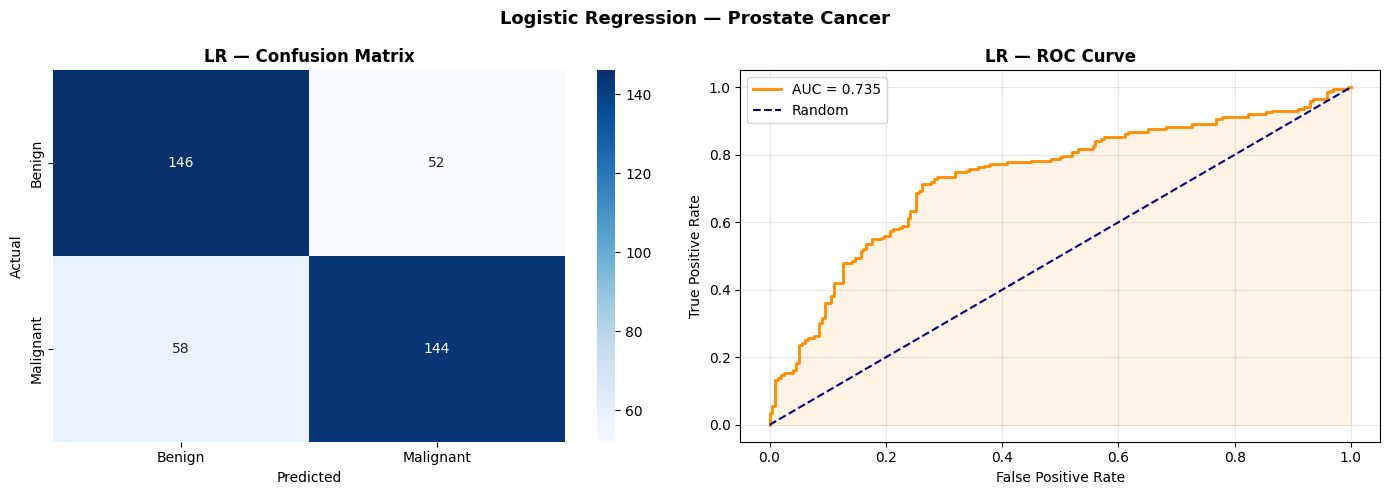

✅ LR complete


In [ ]:
print("=" * 60)
print("MODEL 1 — LOGISTIC REGRESSION")
print("=" * 60)

lr_model = LogisticRegression(max_iter=1000, random_state=42)

# Cross-validate first
cv_lr = cross_val_score(lr_model, X_train_bal, y_train_bal,
                        cv=cv, scoring='roc_auc')
print(f"\n🔁 5-Fold CV ROC-AUC : {cv_lr.mean():.4f} ± {cv_lr.std():.4f}")
print(f"   Individual folds  : {[round(s, 4) for s in cv_lr]}")

# Train
lr_model.fit(X_train_bal, y_train_bal)

# Predict
y_pred_lr = lr_model.predict(X_test_scaled)
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

# Metrics
acc_lr     = accuracy_score(y_test, y_pred_lr)
rec_lr     = recall_score(y_test, y_pred_lr)
f1_lr      = f1_score(y_test, y_pred_lr)
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)

print(f"\n📊 LR — Test Performance:")
print(f"   Accuracy             : {acc_lr:.4f}")
print(f"   Recall (Sensitivity) : {rec_lr:.4f}  ← CRITICAL FOR CANCER SCREENING")
print(f"   F1-Score             : {f1_lr:.4f}")
print(f"   ROC-AUC              : {roc_auc_lr:.4f}")
print(f"\n   Classification Report:")
print(classification_report(y_test, y_pred_lr,
                            target_names=['Benign', 'Malignant']))

# Plots — side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(confusion_matrix(y_test, y_pred_lr),
            annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Benign', 'Malignant'],
            yticklabels=['Benign', 'Malignant'])
axes[0].set_title('LR — Confusion Matrix', fontweight='bold')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
axes[1].plot(fpr_lr, tpr_lr, color='darkorange', lw=2,
             label=f'AUC = {roc_auc_lr:.3f}')
axes[1].plot([0,1],[0,1],'navy',lw=1.5,linestyle='--',label='Random')
axes[1].fill_between(fpr_lr, tpr_lr, alpha=0.1, color='darkorange')
axes[1].set_title('LR — ROC Curve', fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.suptitle('Logistic Regression — Prostate Cancer', 
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('prostate_lr_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ LR complete")

CELL 10 — KNN

MODEL 2 — K-NEAREST NEIGHBORS (KNN)

🔍 Finding optimal K via 5-Fold CV (scoring = Recall)...
   ✅ Best K : 15  (CV Recall : 0.6752)
   5-Fold CV ROC-AUC : 0.6882 ± 0.0306
   Individual folds  : [np.float64(0.6907), np.float64(0.7285), np.float64(0.6556), np.float64(0.6519), np.float64(0.7143)]

📊 KNN — Test Performance:
   Accuracy             : 0.6875
   Recall (Sensitivity) : 0.6931  ← CRITICAL FOR CANCER SCREENING
   F1-Score             : 0.6914
   ROC-AUC              : 0.7120

   Classification Report:
              precision    recall  f1-score   support

      Benign       0.69      0.68      0.68       198
   Malignant       0.69      0.69      0.69       202

    accuracy                           0.69       400
   macro avg       0.69      0.69      0.69       400
weighted avg       0.69      0.69      0.69       400



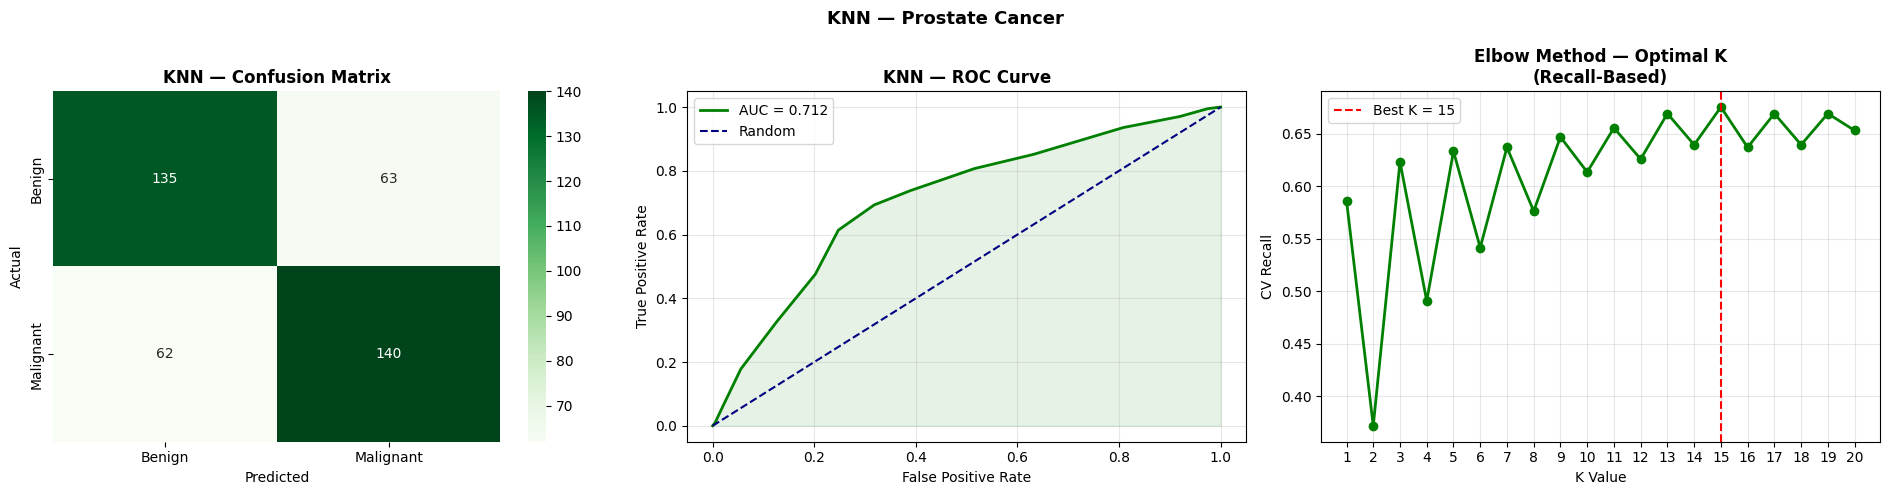

✅ KNN complete


In [19]:
print("=" * 60)
print("MODEL 2 — K-NEAREST NEIGHBORS (KNN)")
print("=" * 60)

# Find best K (optimise for Recall)
print("\n🔍 Finding optimal K via 5-Fold CV (scoring = Recall)...")
k_range     = range(1, 21)
cv_scores_k = []

for k in k_range:
    scores = cross_val_score(KNeighborsClassifier(n_neighbors=k),
                             X_train_bal, y_train_bal,
                             cv=cv, scoring='recall')
    cv_scores_k.append(scores.mean())

best_k = list(k_range)[np.argmax(cv_scores_k)]
print(f"   ✅ Best K : {best_k}  (CV Recall : {max(cv_scores_k):.4f})")

cv_knn = cross_val_score(KNeighborsClassifier(n_neighbors=best_k),
                         X_train_bal, y_train_bal,
                         cv=cv, scoring='roc_auc')
print(f"   5-Fold CV ROC-AUC : {cv_knn.mean():.4f} ± {cv_knn.std():.4f}")
print(f"   Individual folds  : {[round(s, 4) for s in cv_knn]}")

# Train
knn_model = KNeighborsClassifier(n_neighbors=best_k)
knn_model.fit(X_train_bal, y_train_bal)

# Predict
y_pred_knn = knn_model.predict(X_test_scaled)
y_prob_knn = knn_model.predict_proba(X_test_scaled)[:, 1]

# Metrics
acc_knn     = accuracy_score(y_test, y_pred_knn)
rec_knn     = recall_score(y_test, y_pred_knn)
f1_knn      = f1_score(y_test, y_pred_knn)
roc_auc_knn = roc_auc_score(y_test, y_prob_knn)

print(f"\n📊 KNN — Test Performance:")
print(f"   Accuracy             : {acc_knn:.4f}")
print(f"   Recall (Sensitivity) : {rec_knn:.4f}  ← CRITICAL FOR CANCER SCREENING")
print(f"   F1-Score             : {f1_knn:.4f}")
print(f"   ROC-AUC              : {roc_auc_knn:.4f}")
print(f"\n   Classification Report:")
print(classification_report(y_test, y_pred_knn,
                            target_names=['Benign', 'Malignant']))

# Plots
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

sns.heatmap(confusion_matrix(y_test, y_pred_knn),
            annot=True, fmt='d', cmap='Greens', ax=axes[0],
            xticklabels=['Benign', 'Malignant'],
            yticklabels=['Benign', 'Malignant'])
axes[0].set_title('KNN — Confusion Matrix', fontweight='bold')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

fpr_knn, tpr_knn, _ = roc_curve(y_test, y_prob_knn)
axes[1].plot(fpr_knn, tpr_knn, color='green', lw=2,
             label=f'AUC = {roc_auc_knn:.3f}')
axes[1].plot([0,1],[0,1],'navy',lw=1.5,linestyle='--',label='Random')
axes[1].fill_between(fpr_knn, tpr_knn, alpha=0.1, color='green')
axes[1].set_title('KNN — ROC Curve', fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].plot(k_range, cv_scores_k, marker='o', color='green', lw=2)
axes[2].axvline(best_k, color='red', linestyle='--',
                label=f'Best K = {best_k}')
axes[2].set_title('Elbow Method — Optimal K\n(Recall-Based)',
                  fontweight='bold')
axes[2].set_xlabel('K Value'); axes[2].set_ylabel('CV Recall')
axes[2].set_xticks(list(k_range)); axes[2].legend()
axes[2].grid(alpha=0.3)

plt.suptitle('KNN — Prostate Cancer', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('prostate_knn_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ KNN complete")

CELL 11 — SVM

MODEL 3 — SUPPORT VECTOR MACHINE (SVM)

🔍 Finding optimal C via 5-Fold CV (scoring = Recall)...
   C = 0.1   → CV Recall : 0.6864
   C = 0.5   → CV Recall : 0.6864
   C = 1.0   → CV Recall : 0.6864
   C = 5.0   → CV Recall : 0.6864
   C = 10.0  → CV Recall : 0.6864

   ✅ Best C : 0.1  (CV Recall : 0.6864)
   5-Fold CV ROC-AUC : 0.6797 ± 0.0363
   Individual folds  : [np.float64(0.7006), np.float64(0.7277), np.float64(0.6366), np.float64(0.6381), np.float64(0.6956)]

📊 SVM — Test Performance:
   Accuracy             : 0.7225
   Recall (Sensitivity) : 0.7129  ← CRITICAL FOR CANCER SCREENING
   F1-Score             : 0.7218
   ROC-AUC              : 0.7268

   Classification Report:
              precision    recall  f1-score   support

      Benign       0.71      0.73      0.72       198
   Malignant       0.73      0.71      0.72       202

    accuracy                           0.72       400
   macro avg       0.72      0.72      0.72       400
weighted avg       0.72      0.72      

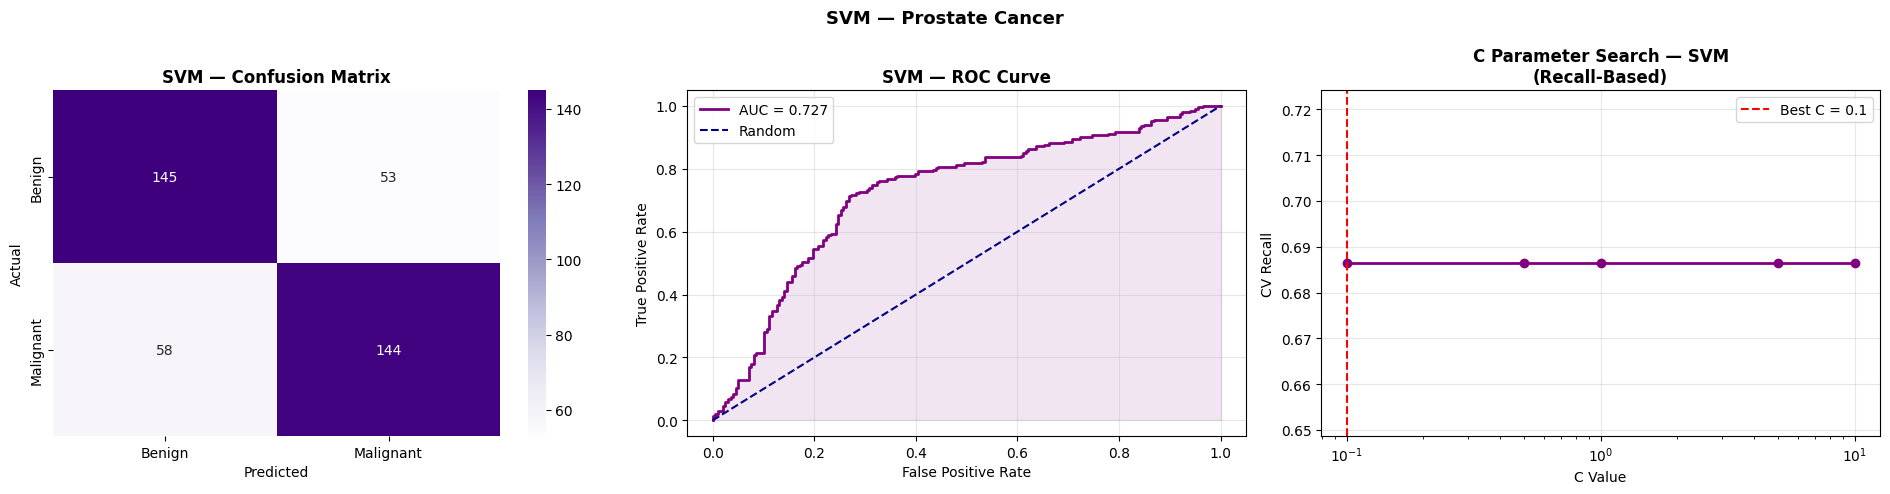

✅ SVM complete


In [20]:
print("=" * 60)
print("MODEL 3 — SUPPORT VECTOR MACHINE (SVM)")
print("=" * 60)

# Find best C (optimise for Recall)
print("\n🔍 Finding optimal C via 5-Fold CV (scoring = Recall)...")
c_values    = [0.1, 0.5, 1.0, 5.0, 10.0]
cv_scores_c = []

for c in c_values:
    scores = cross_val_score(
        SVC(kernel='rbf', C=c, gamma='scale',
            probability=True, random_state=42),
        X_train_bal, y_train_bal, cv=cv, scoring='recall')
    cv_scores_c.append(scores.mean())
    print(f"   C = {c:<5} → CV Recall : {scores.mean():.4f}")

best_c = c_values[np.argmax(cv_scores_c)]
print(f"\n   ✅ Best C : {best_c}  (CV Recall : {max(cv_scores_c):.4f})")

cv_svm = cross_val_score(
    SVC(kernel='rbf', C=best_c, gamma='scale',
        probability=True, random_state=42),
    X_train_bal, y_train_bal, cv=cv, scoring='roc_auc')
print(f"   5-Fold CV ROC-AUC : {cv_svm.mean():.4f} ± {cv_svm.std():.4f}")
print(f"   Individual folds  : {[round(s, 4) for s in cv_svm]}")

# Train — no class_weight='balanced' since SMOTE already handled it
svm_model = SVC(kernel='rbf', C=best_c, gamma='scale',
                probability=True, random_state=42)
svm_model.fit(X_train_bal, y_train_bal)

# Predict
y_pred_svm = svm_model.predict(X_test_scaled)
y_prob_svm = svm_model.predict_proba(X_test_scaled)[:, 1]

# Metrics
acc_svm     = accuracy_score(y_test, y_pred_svm)
rec_svm     = recall_score(y_test, y_pred_svm)
f1_svm      = f1_score(y_test, y_pred_svm)
roc_auc_svm = roc_auc_score(y_test, y_prob_svm)

print(f"\n📊 SVM — Test Performance:")
print(f"   Accuracy             : {acc_svm:.4f}")
print(f"   Recall (Sensitivity) : {rec_svm:.4f}  ← CRITICAL FOR CANCER SCREENING")
print(f"   F1-Score             : {f1_svm:.4f}")
print(f"   ROC-AUC              : {roc_auc_svm:.4f}")
print(f"\n   Classification Report:")
print(classification_report(y_test, y_pred_svm,
                            target_names=['Benign', 'Malignant']))

# Plots
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

sns.heatmap(confusion_matrix(y_test, y_pred_svm),
            annot=True, fmt='d', cmap='Purples', ax=axes[0],
            xticklabels=['Benign', 'Malignant'],
            yticklabels=['Benign', 'Malignant'])
axes[0].set_title('SVM — Confusion Matrix', fontweight='bold')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
axes[1].plot(fpr_svm, tpr_svm, color='purple', lw=2,
             label=f'AUC = {roc_auc_svm:.3f}')
axes[1].plot([0,1],[0,1],'navy',lw=1.5,linestyle='--',label='Random')
axes[1].fill_between(fpr_svm, tpr_svm, alpha=0.1, color='purple')
axes[1].set_title('SVM — ROC Curve', fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].plot(c_values, cv_scores_c, marker='o', color='purple', lw=2)
axes[2].axvline(best_c, color='red', linestyle='--',
                label=f'Best C = {best_c}')
axes[2].set_title('C Parameter Search — SVM\n(Recall-Based)',
                  fontweight='bold')
axes[2].set_xlabel('C Value'); axes[2].set_ylabel('CV Recall')
axes[2].set_xscale('log'); axes[2].legend()
axes[2].grid(alpha=0.3)

plt.suptitle('SVM — Prostate Cancer', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('prostate_svm_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ SVM complete")

CELL 12 — Final Comparison


  FINAL MODEL COMPARISON — Prostate Cancer Prediction
  Metric                 |   Log. Reg   |  KNN (K=15)  | SVM (C=0.1) 
  -----------------------+--------------+--------------+-------------
  Accuracy               |    0.7225    |    0.6875    |    0.7225   
  Recall (Sensitivity)   |    0.7129    |    0.6931    |    0.7129   
  F1-Score               |    0.7218    |    0.6914    |    0.7218   
  ROC-AUC                |    0.7175    |    0.7120    |    0.7268   
  CV ROC-AUC             |    0.6806    |    0.6882    |    0.6797   
  💡 Prioritise RECALL — missing a malignant case is
     clinically more dangerous than a false alarm.


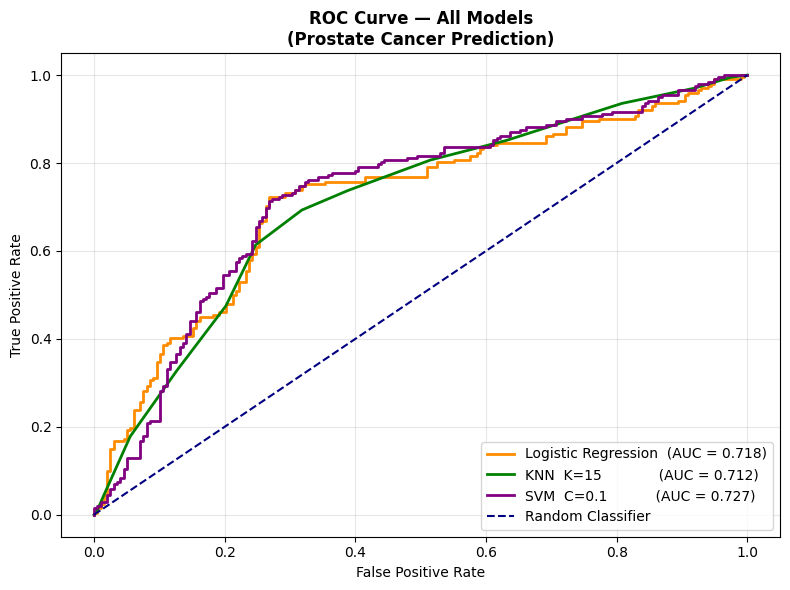


 Prostate Cancer modelling complete!


In [21]:
print("\n" + "=" * 68)
print("  FINAL MODEL COMPARISON — Prostate Cancer Prediction")
print("=" * 68)
print(f"  {'Metric':<22} | {'Log. Reg':^12} | {'KNN (K='+str(best_k)+')':^12} | {'SVM (C='+str(best_c)+')':^12}")
print(f"  {'-'*22}-+-{'-'*12}-+-{'-'*12}-+-{'-'*12}")
print(f"  {'Accuracy':<22} | {acc_lr:^12.4f} | {acc_knn:^12.4f} | {acc_svm:^12.4f}")
print(f"  {'Recall (Sensitivity)':<22} | {rec_lr:^12.4f} | {rec_knn:^12.4f} | {rec_svm:^12.4f}")
print(f"  {'F1-Score':<22} | {f1_lr:^12.4f} | {f1_knn:^12.4f} | {f1_svm:^12.4f}")
print(f"  {'ROC-AUC':<22} | {roc_auc_lr:^12.4f} | {roc_auc_knn:^12.4f} | {roc_auc_svm:^12.4f}")
print(f"  {'CV ROC-AUC':<22} | {cv_lr.mean():^12.4f} | {cv_knn.mean():^12.4f} | {cv_svm.mean():^12.4f}")
print("=" * 68)
print("  💡 Prioritise RECALL — missing a malignant case is")
print("     clinically more dangerous than a false alarm.")
print("=" * 68)

# Combined ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr_lr,  tpr_lr,  color='darkorange', lw=2,
         label=f'Logistic Regression  (AUC = {roc_auc_lr:.3f})')
plt.plot(fpr_knn, tpr_knn, color='green',      lw=2,
         label=f'KNN  K={best_k}             (AUC = {roc_auc_knn:.3f})')
plt.plot(fpr_svm, tpr_svm, color='purple',     lw=2,
         label=f'SVM  C={best_c}           (AUC = {roc_auc_svm:.3f})')
plt.plot([0,1],[0,1],'navy',lw=1.5,linestyle='--',label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — All Models\n(Prostate Cancer Prediction)',
          fontweight='bold')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('prostate_comparison_roc.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n Prostate Cancer modelling complete!")